In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def visualize_noise_analysis(image_path, grid_rows=40, grid_cols=40):
    # 1. Load image and calculate the noise residual
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Could not load image at {image_path}")
        
    smoothed = cv2.medianBlur(img, 5)
    residual = cv2.absdiff(img, smoothed)
    
    # 2. Calculate variance for each quadrant
    h, w = img.shape
    heatmap_data = np.zeros((grid_rows, grid_cols), dtype=np.float32)
    quad_h, quad_w = h // grid_rows, w // grid_cols
    
    for row in range(grid_rows):
        for col in range(grid_cols):
            quadrant = residual[row*quad_h:(row+1)*quad_h, col*quad_w:(col+1)*quad_w]
            heatmap_data[row, col] = np.var(quadrant)
            
    # 3. Render the Heatmap
    heatmap_norm = cv2.normalize(heatmap_data, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)
    heatmap_resized = cv2.resize(heatmap_norm, (w, h), interpolation=cv2.INTER_NEAREST)
    heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)
    
    img_colored = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    overlay = cv2.addWeighted(img_colored, 0.6, heatmap_colored, 0.4, 0)
    
    # 4. Convert BGR to RGB for correct Matplotlib rendering
    overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
    
    # 5. Plot the three stages side-by-side
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Original Image
    axes[0].imshow(img, cmap='gray')
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    
    # Isolated Noise (using 'magma' colormap to make the grain pop visually)
    axes[1].imshow(residual, cmap='magma') 
    axes[1].set_title('Isolated High-Frequency Noise')
    axes[1].axis('off')
    
    # Heatmap Overlay
    axes[2].imshow(overlay_rgb)
    axes[2].set_title(f'Noise Variance Heatmap ({grid_rows}x{grid_cols})')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Execute the visualization
# visualize_noise_analysis("path/to/your/bat_wing_image.png", grid_rows=2, grid_cols=2)

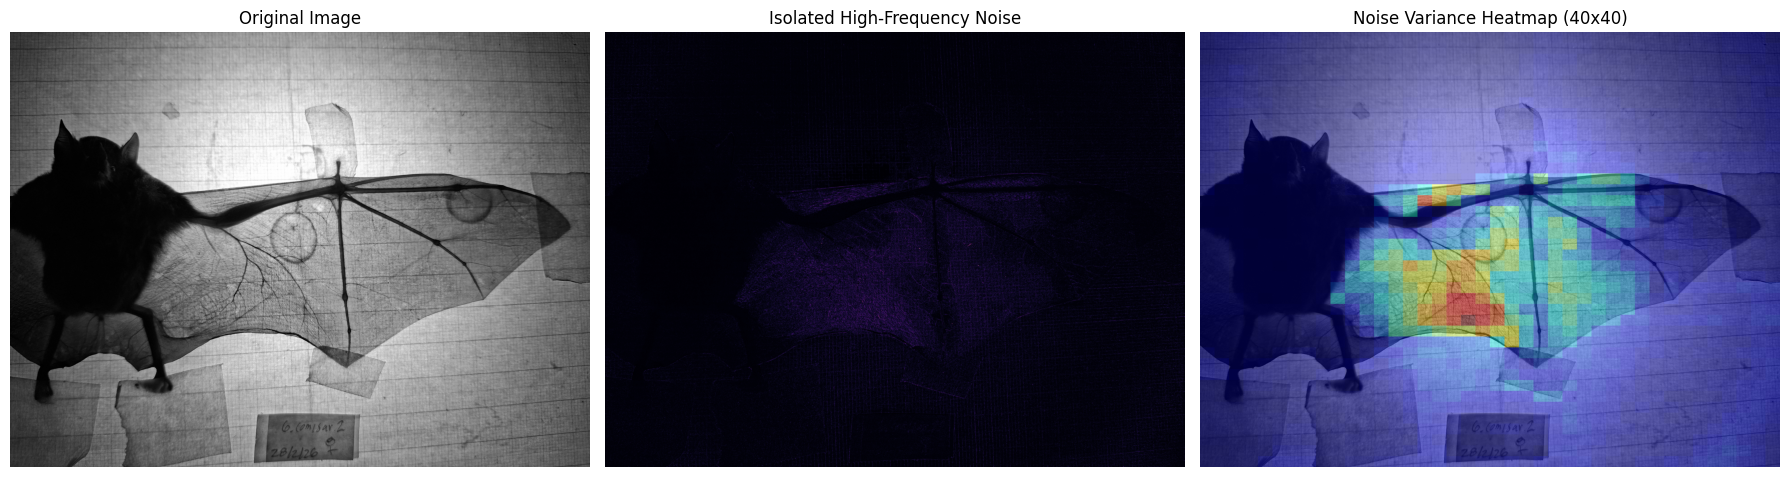

In [6]:
visualize_noise_analysis("Glos_comm.jpg")